# 01 — Análisis exploratorio de datos

Lectura automática de medidores de agua y energía — Visión por Computadora II (CEIA, FIUBA).

Se analizan los conjuntos de datos del proyecto, primero los de agua y después los de energía:

| Dataset | Servicio | Uso | Versión | Licencia |
|---|---|---|---|---|
| [Toloka Water Meters](https://www.kaggle.com/datasets/tapakah68/yandextoloka-water-meters-dataset) (Kaggle) | agua | Entrenamiento de la segmentación del visor | — | CC BY-NC-ND 4.0 |
| [water-meter-dataset](https://universe.roboflow.com/water-meter-yfzw4/water-meter-dataset) (Roboflow, yfzw4) | agua | Detección de dígitos y visor derivado para la segmentación | v3 | CC BY 4.0 |
| [meter-digits-5srka](https://universe.roboflow.com/mohammad-annus/meter-digits-5srka) (Roboflow) | energía | Dígitos LCD para el detector de dígitos | v7 | CC BY 4.0 |
| [meter-digits-frvqn](https://universe.roboflow.com/meter-i5vud/meter-digits-frvqn) (Roboflow) | energía | Dígitos LCD para el detector de dígitos | v2 | CC BY 4.0 |
| Fotos de campo CEML de agua (`data/ceml/`) | agua | Prueba en condiciones reales y clasificador de formato | — | uso académico |
| Fotos de campo CEML de energía (`data/ceml_energia/`) | energía | Segmentación, dígitos y formato, y prueba (muestra aparte) | — | uso académico |

Los públicos se descargan en `data/raw/` con `scripts/download_data.py`; las fotos de campo están en el repositorio, anonimizadas. Los visores de CEML y los dígitos de energía se etiquetaron en proyectos privados de Roboflow (SAM 3 con revisión manual), porque las fotos son de clientes de la cooperativa. Los modelos parten de pesos preentrenados públicos: YOLOv8n y YOLO11n en COCO (Ultralytics), Mask R-CNN R50-FPN en COCO (torchvision) y MobileNetV3-small en ImageNet (torchvision). El detalle de cada fuente está en [data/README.md](../data/README.md).

**Preguntas que guían el análisis:** ¿en qué se parecen las fotos de entrenamiento a las de campo? ¿Qué tan inclinado y qué tan chico está el visor? ¿Cómo se reparten los dígitos? ¿En qué se diferencian los medidores de energía de los de agua?

**Ejecución:** funciona en local (desde la carpeta `notebooks/`) y en Google Colab. En Colab, cargar la API key de Roboflow como *Secret* con el nombre `ROBOFLOW_API_KEY`.

In [1]:
# Configuración del entorno: local o Google Colab.
import os
import sys
import subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/martinlacheski/ceia-vpc-2.git"

if IN_COLAB:
    if not Path("ceia-vpc-2").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("ceia-vpc-2")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import userdata
    try:
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        print("Aviso: falta el Secret ROBOFLOW_API_KEY; no se podrá descargar water-meter-dataset.")
elif Path.cwd().name == "notebooks":
    # En local el notebook se abre desde notebooks/: se trabaja desde la raíz del repo.
    os.chdir("..")

print("Directorio de trabajo:", Path.cwd(), "| Colab:", IN_COLAB)

Directorio de trabajo: /home/martin/Code/ceia-vpc-2 | Colab: False


In [2]:
# Descarga de los datasets públicos (si ya están en data/raw/, no se descarga nada).
result = subprocess.run([sys.executable, "scripts/download_data.py"], capture_output=True, text=True)
print(result.stdout, result.stderr)
# Dígitos LCD públicos de energía (meter-digits-5srka y frvqn); necesitan ROBOFLOW_API_KEY.
result = subprocess.run([sys.executable, "scripts/download_data.py", "--only", "energia"], capture_output=True, text=True)
print(result.stdout, result.stderr)

Toloka ya está en data/raw/toloka
water-meter-dataset ya está en data/raw/roboflow_water_meter
 
meter-digits-5srka ya está en data/raw/energia/meter-digits-5srka
meter-digits-frvqn ya está en data/raw/energia/meter-digits-frvqn
 


In [3]:
import ast
import random
from collections import Counter

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("jpeg")  # figuras livianas: muchas son fotos

sys.path.insert(0, "src")
sys.path.insert(0, "scripts")
from meter_reader.layout import model_input  # noqa: E402
from meter_reader.rectify import rectify  # noqa: E402
from prepare_digits import crop_labels, digit_classes, keep_digits  # noqa: E402
from prepare_seg_combined import display_polygon  # noqa: E402

random.seed(42)
TOLOKA = Path("data/raw/toloka")
ROBOFLOW = Path("data/raw/roboflow_water_meter")
CEML = Path("data/ceml")
ENERGY = Path("data/ceml_energia")
LCD = Path("data/raw/energia")


def display_geometry(points: np.ndarray, width: int, height: int) -> tuple[float, float]:
    """Devuelve (fracción del área de la imagen, inclinación del visor en grados 0-90).

    La inclinación es el ángulo del lado largo del rectángulo mínimo que contiene
    al polígono, medido respecto de la horizontal: 0 = visor horizontal, 90 = vertical.
    """
    area = cv2.contourArea(points.astype(np.float32)) / (width * height)
    (_, _), (w, h), angle = cv2.minAreaRect(points.astype(np.float32))
    if w < h:
        angle += 90
    angle = angle % 180
    return area, min(angle, 180 - angle)


def yolo_polygon(label: Path, width: int, height: int) -> np.ndarray:
    """Lee la primera línea de una etiqueta YOLO-seg y la pasa a píxeles."""
    values = list(map(float, label.read_text().split()[1:]))
    return np.array(values).reshape(-1, 2) * [width, height]

## 1. Toloka (segmentación del visor)

1244 fotos de medidores de agua, con el polígono del visor anotado a mano y la lectura en el nombre del archivo. Es el conjunto principal para entrenar la segmentación. Para cada foto se mide el **área del visor** (fracción de la imagen) y su **inclinación** (ángulo del lado largo del rectángulo mínimo que lo contiene, respecto de la horizontal).

In [4]:
toloka = pd.read_csv(TOLOKA / "data.csv")
rows = []
for r in toloka.itertuples():
    with Image.open(TOLOKA / "images" / r.photo_name) as im:
        w, h = im.size
    pts = np.array([[p["x"] * w, p["y"] * h] for p in ast.literal_eval(r.location)["data"]])
    area, tilt = display_geometry(pts, w, h)
    # La lectura exacta está en el nombre: id_<n>_value_<entero>_<decimales>.jpg
    integer = r.photo_name.split("_value_")[1].split("_")[0]
    rows.append({"file": r.photo_name, "width": w, "height": h, "area": area, "tilt": tilt,
                 "integer_digits": len(integer)})
toloka_geo = pd.DataFrame(rows)
print(f"Imágenes: {len(toloka_geo)}")
print("Resoluciones más frecuentes:", Counter(zip(toloka_geo.width, toloka_geo.height)).most_common(3))
toloka_geo[["area", "tilt"]].describe().round(3)

Imágenes: 1244
Resoluciones más frecuentes: [((1000, 1333), 716), ((1333, 1000), 346), ((1778, 1000), 61)]


,area,tilt
count,1244.000,1244.000
mean,0.023,11.106
std,0.013,21.218
min,0.003,0.000
25%,0.013,1.141
50%,0.020,2.928
75%,0.028,8.036
max,0.150,90.000


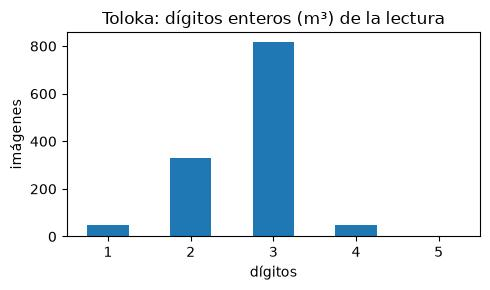

In [5]:
ax = toloka_geo["integer_digits"].value_counts().sort_index().plot.bar(figsize=(5, 3), rot=0)
ax.set(title="Toloka: dígitos enteros (m³) de la lectura", xlabel="dígitos", ylabel="imágenes")
plt.tight_layout()
plt.show()

La mayoría de los visores están casi horizontales (mediana de 3°), pero la cola llega a 90°: hay fotos con el visor vertical. El visor es chico, un 2 % del área en mediana.

## 2. Fotos de campo CEML de agua (prueba en condiciones reales)

324 fotos de medidores de agua de la cooperativa, tomadas por los lecturistas en la ruta. Son las fotos de prueba del pipeline de agua: el visor se etiquetó (SAM 3 con revisión manual) y la lectura se verificó a mano. Las coordenadas y direcciones reales no se usan.

In [6]:
meta = pd.read_csv(CEML / "metadata.csv")
rows = []
for r in meta.itertuples():
    with Image.open(CEML / "images" / r.file) as im:
        w, h = im.size
    area, tilt = display_geometry(yolo_polygon(CEML / "labels" / f"{Path(r.file).stem}.txt", w, h), w, h)
    rows.append({"file": r.file, "width": w, "height": h, "area": area, "tilt": tilt})
ceml_geo = pd.DataFrame(rows)
print(f"Imágenes: {len(ceml_geo)} | medidores distintos: {meta.meter_id.nunique()}")
print("Fotos por mes:", meta.month.value_counts().sort_index().to_dict())
print("Fotos por ruta:", meta.route.value_counts().to_dict())
ceml_geo[["area", "tilt"]].describe().round(3)

Imágenes: 324 | medidores distintos: 314
Fotos por mes: {'2018-08': 19, '2018-09': 18, '2018-10': 20, '2018-11': 17, '2018-12': 19, '2019-01': 22, '2019-02': 20, '2019-03': 12, '2019-04': 27, '2019-05': 19, '2019-06': 19, '2019-07': 19, '2019-08': 13, '2019-09': 24, '2019-10': 22, '2019-11': 8, '2019-12': 26}
Fotos por ruta: {80: 163, 90: 161}


,area,tilt
count,324.000,324.000
mean,0.021,10.516
std,0.015,23.650
min,0.002,0.000
25%,0.011,0.874
50%,0.017,1.945
75%,0.026,4.772
max,0.107,90.000


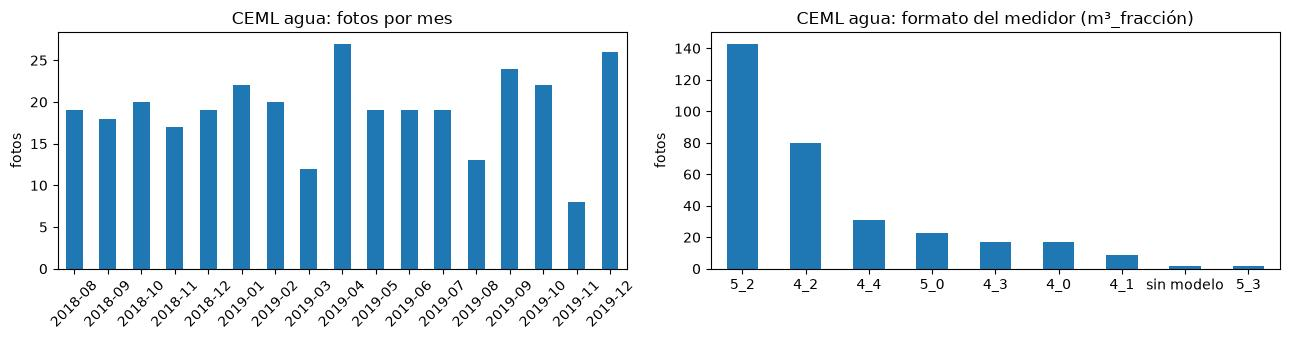

In [7]:
water = pd.read_csv(CEML / "readings.csv", dtype=str).fillna("")
water["formato"] = water["modelo"].str.extract(r"_(\d_\d)$")[0].fillna("sin modelo")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
meta.month.value_counts().sort_index().plot.bar(ax=axes[0], rot=45)
axes[0].set(title="CEML agua: fotos por mes", xlabel="", ylabel="fotos")
water["formato"].value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="CEML agua: formato del medidor (m³_fracción)", xlabel="", ylabel="fotos")
plt.tight_layout()
plt.show()

El formato (`<dígitos de m³>_<dígitos de fracción>`) decide dónde va el punto de la lectura. Dos de cada tres fotos son `5_2` o `4_2`; los demás formatos tienen pocas fotos, y eso pesa en el clasificador de formato. Abajo, un ejemplo de cada formato tal como lo ve el clasificador: el visor enderezado con su entorno (logo, marco, tapa), que es lo que distingue a un modelo de otro.

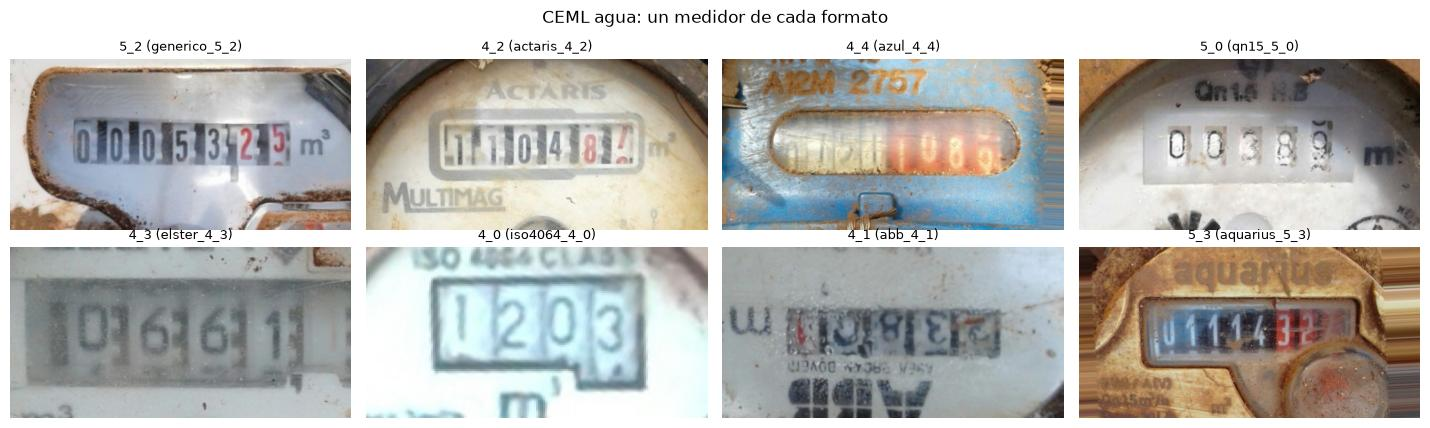

In [8]:
def format_gallery(sheet, root, title, per_row=4):
    """Un ejemplo por formato: la entrada del clasificador (visor enderezado con su entorno)."""
    picks = sheet[sheet["formato"] != "sin modelo"].groupby("formato").head(1)
    picks = picks.set_index("formato").loc[sheet["formato"].value_counts().index.drop("sin modelo", errors="ignore")]
    rows = -(-len(picks) // per_row)
    fig, axes = plt.subplots(rows, per_row, figsize=(3.6 * per_row, 2.2 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, (fmt, r) in zip(axes.flat, picks.iterrows()):
        image = cv2.imread(str(root / "images" / r.file))
        polygon = yolo_polygon(root / "labels" / f"{Path(r.file).stem}.txt", image.shape[1], image.shape[0])
        ax.imshow(cv2.cvtColor(model_input(image, polygon.astype(np.float32)), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{fmt} ({r.modelo})", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


format_gallery(water, CEML, "CEML agua: un medidor de cada formato")

## 3. Comparación de dominios: Toloka contra CEML de agua

La inclinación del visor y su tamaño relativo en la imagen son las dos diferencias que más pueden afectar al pipeline: un visor inclinado complica la lectura de los dígitos (motiva la rectificación) y un visor chico complica la segmentación.

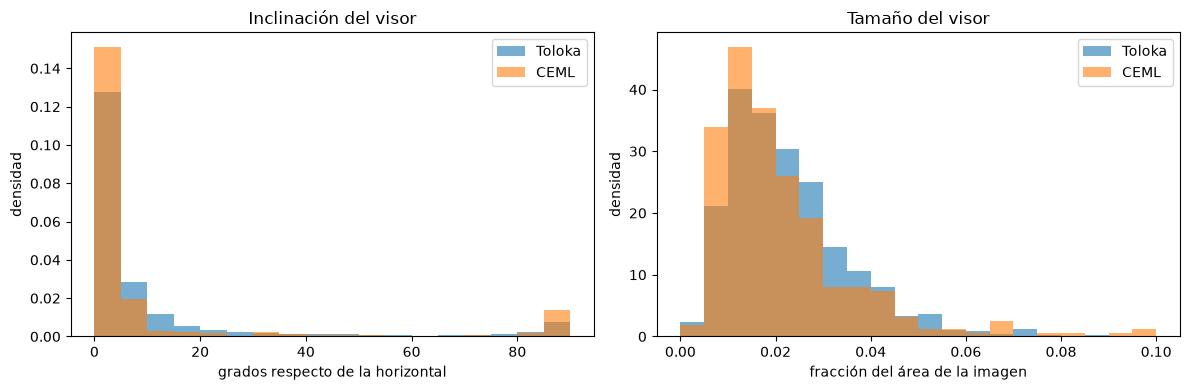

,Toloka,CEML
inclinación mediana (°),2.9,1.9
% visores inclinados > 15°,16.0,13.0
área mediana del visor (%),2.0,1.7


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins_tilt = np.linspace(0, 90, 19)
axes[0].hist(toloka_geo.tilt, bins=bins_tilt, alpha=0.6, density=True, label="Toloka")
axes[0].hist(ceml_geo.tilt, bins=bins_tilt, alpha=0.6, density=True, label="CEML")
axes[0].set(title="Inclinación del visor", xlabel="grados respecto de la horizontal", ylabel="densidad")
axes[0].legend()

bins_area = np.linspace(0, 0.1, 21)
axes[1].hist(toloka_geo.area.clip(upper=0.1), bins=bins_area, alpha=0.6, density=True, label="Toloka")
axes[1].hist(ceml_geo.area.clip(upper=0.1), bins=bins_area, alpha=0.6, density=True, label="CEML")
axes[1].set(title="Tamaño del visor", xlabel="fracción del área de la imagen", ylabel="densidad")
axes[1].legend()
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "Toloka": [toloka_geo.tilt.median(), (toloka_geo.tilt > 15).mean() * 100, toloka_geo.area.median() * 100],
    "CEML": [ceml_geo.tilt.median(), (ceml_geo.tilt > 15).mean() * 100, ceml_geo.area.median() * 100],
}, index=["inclinación mediana (°)", "% visores inclinados > 15°", "área mediana del visor (%)"])
summary.round(1)

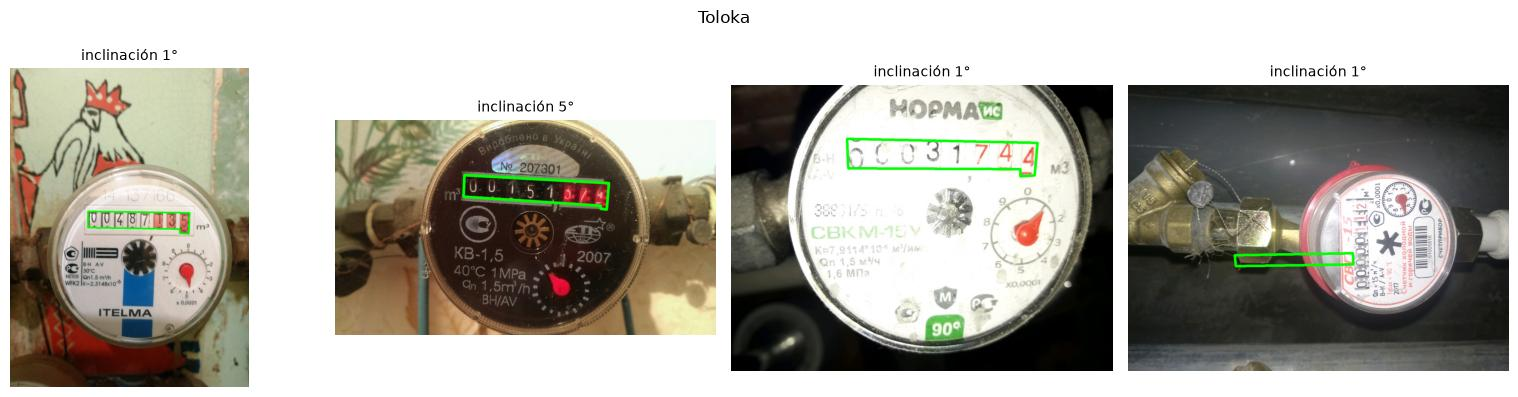

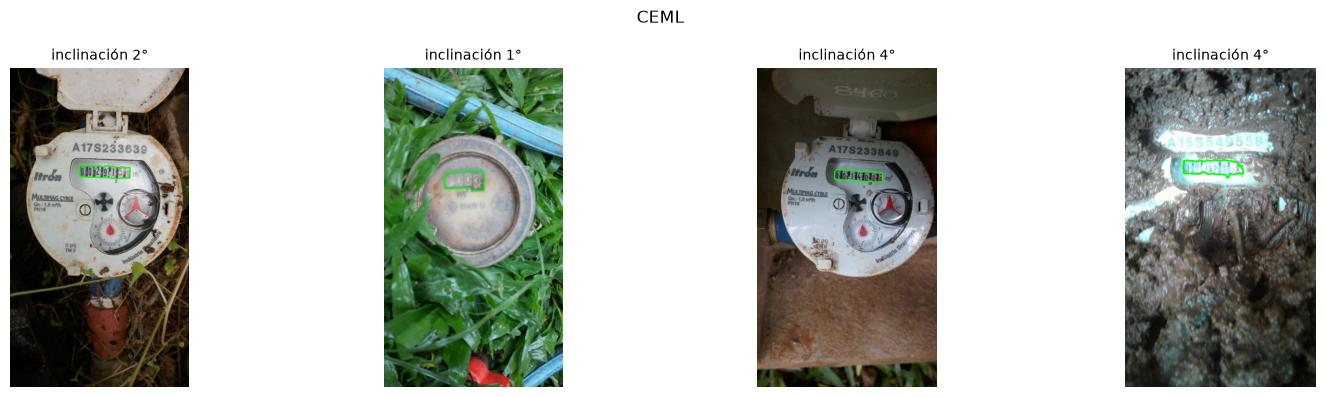

In [10]:
def show_samples(df, images_dir, polygon_fn, title, n=4):
    """Muestra n imágenes al azar con el polígono del visor superpuesto."""
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4))
    for ax, r in zip(axes, df.sample(n, random_state=42).itertuples()):
        img = np.array(Image.open(images_dir / r.file).convert("RGB"))
        pts = polygon_fn(r).astype(np.int32)
        cv2.polylines(img, [pts], True, (0, 255, 0), max(3, img.shape[1] // 150))
        ax.imshow(img)
        ax.set_title(f"inclinación {r.tilt:.0f}°", fontsize=10)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


toloka_polys = {r.photo_name: ast.literal_eval(r.location)["data"] for r in toloka.itertuples()}
show_samples(toloka_geo, TOLOKA / "images",
             lambda r: np.array([[p["x"] * r.width, p["y"] * r.height] for p in toloka_polys[r.file]]),
             "Toloka")
show_samples(ceml_geo, CEML / "images",
             lambda r: yolo_polygon(CEML / "labels" / f"{Path(r.file).stem}.txt", r.width, r.height),
             "CEML")

En CEML aparecen barro, tapas a medio abrir, reflejos y fotos tomadas desde cualquier lado de la caja. La geometría es parecida a la de Toloka; la diferencia está en la apariencia.

## 4. water-meter-dataset v3 (detección de dígitos)

Fotos de medidores de agua con una caja por dígito (clases 0–9, más algunas clases auxiliares que no se usan). Para entrenar el detector, cada foto se recorta al visor y se rectifica igual que en el pipeline (`scripts/prepare_digits.py`), así el detector ve el mismo encuadre que en la lectura.

Imágenes por split: {'train': 7504, 'valid': 795, 'test': 679}


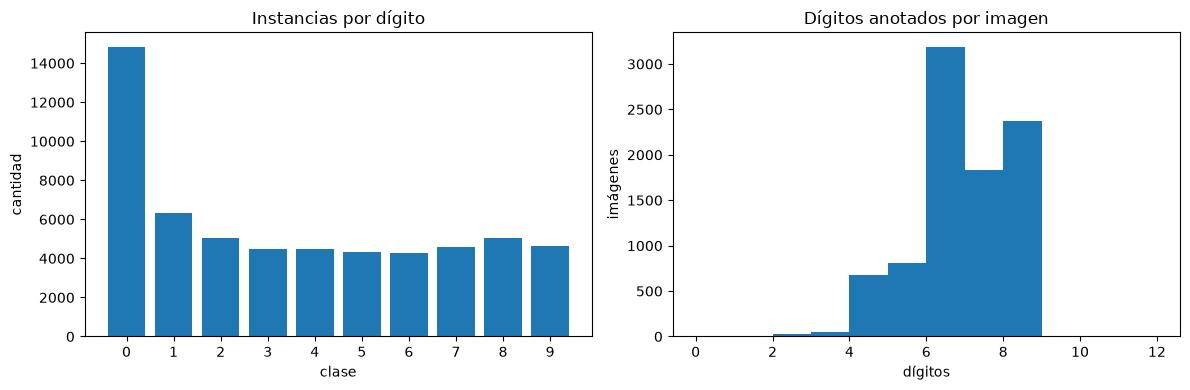

In [11]:
if not (ROBOFLOW / "data.yaml").exists():
    print("water-meter-dataset no está descargado: se omite esta sección.")
else:
    import yaml
    names = yaml.safe_load((ROBOFLOW / "data.yaml").read_text())["names"]
    split_counts, class_counts, digits_per_image = {}, Counter(), []
    for split in ("train", "valid", "test"):
        labels = list((ROBOFLOW / split / "labels").glob("*.txt"))
        split_counts[split] = len(labels)
        for label in labels:
            classes = [int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()]
            class_counts.update(classes)
            digits_per_image.append(sum(names[c].isdigit() for c in classes))
    print("Imágenes por split:", split_counts)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    digit_ids = [i for i, n in enumerate(names) if n.isdigit()]
    axes[0].bar([names[i] for i in digit_ids], [class_counts[i] for i in digit_ids])
    axes[0].set(title="Instancias por dígito", xlabel="clase", ylabel="cantidad")
    axes[1].hist(digits_per_image, bins=range(0, 13))
    axes[1].set(title="Dígitos anotados por imagen", xlabel="dígitos", ylabel="imágenes")
    plt.tight_layout()
    plt.show()

**Cómo se usa water-meter-dataset.** No anota el visor, pero sí cada dígito. Se aprovecha de dos formas:

1. **Visor derivado** (para la segmentación): el rectángulo rotado mínimo que contiene todos los dígitos, con un margen, se usa como polígono del visor (`scripts/prepare_seg_combined.py`). Así se suman miles de medidores distintos al entrenamiento de la segmentación.
2. **Recorte rectificado** (para los dígitos): la foto se endereza con ese visor y las cajas de los dígitos se llevan al recorte (`scripts/prepare_digits.py`). El detector se entrena viendo lo mismo que verá en el pipeline.

Abajo, tres fotos: los dígitos anotados (verde) con el visor derivado (amarillo), y el recorte rectificado con sus cajas.

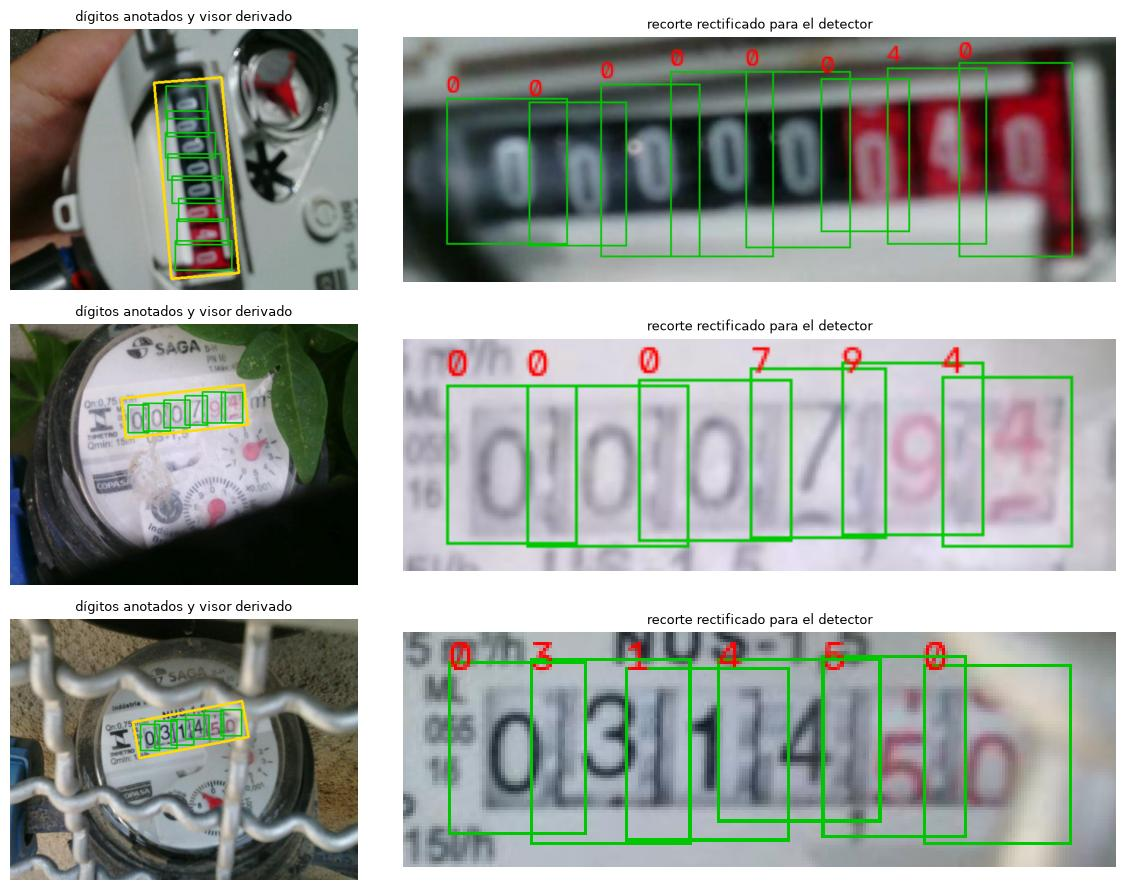

In [12]:
if (ROBOFLOW / "data.yaml").exists():
    classes = digit_classes(ROBOFLOW)
    files = sorted((ROBOFLOW / "test" / "images").glob("*"))
    fig, grid = plt.subplots(3, 2, figsize=(12, 9), gridspec_kw={"width_ratios": [1, 1.5]})
    for (axes, image_path) in zip(grid, random.Random(3).sample(files, 3)):
        image = cv2.imread(str(image_path))
        h, w = image.shape[:2]
        text = keep_digits((ROBOFLOW / "test" / "labels" / f"{image_path.stem}.txt").read_text(), classes)
        polygon = np.array(display_polygon(text, w, h)).reshape(-1, 2) * [w, h]
        overlay = image.copy()
        for line in text.splitlines():
            values = list(map(float, line.split()[1:]))
            if len(values) == 4:
                cx, cy, bw, bh = values
                corners = np.array([[cx - bw / 2, cy - bh / 2], [cx + bw / 2, cy - bh / 2],
                                    [cx + bw / 2, cy + bh / 2], [cx - bw / 2, cy + bh / 2]])
            else:
                corners = np.array(values).reshape(-1, 2)
            cv2.polylines(overlay, [(corners * [w, h]).astype(np.int32)], True, (0, 200, 0), 2)
        cv2.polylines(overlay, [polygon.astype(np.int32)], True, (0, 220, 255), 3)
        crop, matrix = rectify(image, polygon, pad=0.05)
        for row in crop_labels(text, matrix, (crop.shape[1], crop.shape[0]), w, h):
            c, cx, cy, bw, bh = row.split()
            cx, cy, bw, bh = float(cx) * crop.shape[1], float(cy) * crop.shape[0], float(bw) * crop.shape[1], float(bh) * crop.shape[0]
            cv2.rectangle(crop, (int(cx - bw / 2), int(cy - bh / 2)), (int(cx + bw / 2), int(cy + bh / 2)), (0, 200, 0), 1)
            cv2.putText(crop, c, (int(cx - bw / 2), max(int(cy - bh / 2) - 3, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1)
        axes[0].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[0].set_title("dígitos anotados y visor derivado", fontsize=9)
        axes[1].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        axes[1].set_title("recorte rectificado para el detector", fontsize=9)
        for ax in axes:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

## 5. Fotos de campo CEML de energía

788 fotos de medidores de energía de la misma cooperativa, de 750 medidores distintos. A diferencia de agua, mezclan dos tipos de visor: **rodillos** (como los de agua, pero de otras marcas) y **LCD de 7 segmentos**. Los medidores están en pared o pilar, no en el piso.

**División.** 201 fotos con la lectura verificada a mano forman la **muestra de prueba** (`muestra=si` en `readings.csv`) y no se usan para entrenar nada. Las demás sirven para entrenar el segmentador, el detector de dígitos y el clasificador de formato, excluyendo también las fotos de los medidores que están en la muestra (el mismo medidor fotografiado otro mes se parece demasiado).

In [13]:
energy = pd.read_csv(ENERGY / "readings.csv", dtype=str).fillna("")
energy_meta = pd.read_csv(ENERGY / "metadata.csv", dtype=str)
energy = energy.merge(energy_meta[["file", "meter_id", "month", "route"]], on="file")
energy["formato"] = energy["modelo"].str.extract(r"_(\d_\d)$")[0].fillna("sin modelo")
sample_meters = set(energy.loc[energy["muestra"] == "si", "meter_id"])
energy["conjunto"] = np.select(
    [energy["muestra"] == "si", energy["meter_id"].isin(sample_meters)],
    ["prueba (muestra)", "excluida (medidor de la muestra)"], default="entrenamiento")

print(f"Fotos: {len(energy)} | medidores distintos: {energy.meter_id.nunique()} | rutas: {energy.route.nunique()} "
      f"| meses: {energy.month.min()} a {energy.month.max()}")
display(pd.crosstab(energy["tipo"], energy["conjunto"], margins=True, margins_name="total"))
pd.crosstab(energy["formato"], energy["tipo"], margins=True, margins_name="total")

Fotos: 788 | medidores distintos: 750 | rutas: 24 | meses: 2018-07 a 2019-12


conjunto,entrenamiento,excluida (medidor de la muestra),prueba (muestra),total
tipo,,,,
lcd,234,3,100,337
rodillos,335,15,101,451
total,569,18,201,788


tipo,lcd,rodillos,total
formato,,,
5_1,26,450,476
6_0,32,0,32
6_1,279,0,279
sin modelo,0,1,1
total,337,451,788


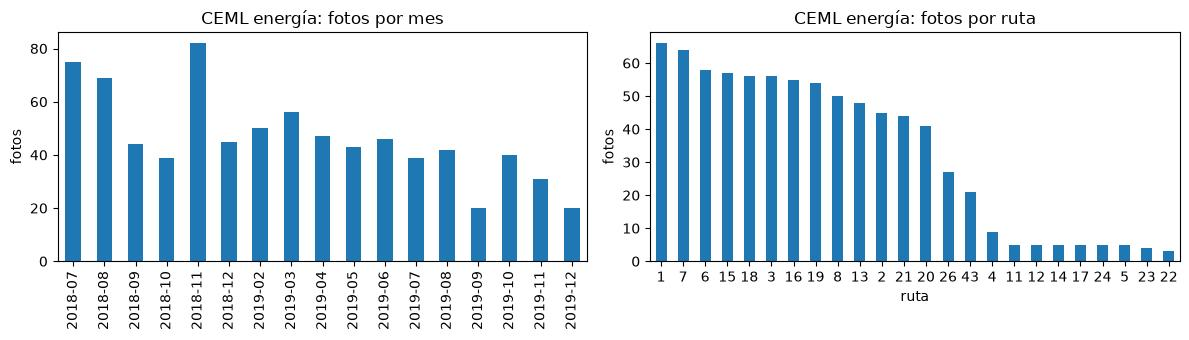

In [14]:
energy["formato_tipo"] = energy["formato"] + " " + energy["tipo"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
energy.month.value_counts().sort_index().plot.bar(ax=axes[0], rot=90)
axes[0].set(title="CEML energía: fotos por mes", xlabel="", ylabel="fotos")
energy.route.value_counts().plot.bar(ax=axes[1], rot=0)
axes[1].set(title="CEML energía: fotos por ruta", xlabel="ruta", ylabel="fotos")
plt.tight_layout()
plt.show()

Los formatos de energía (`<dígitos enteros>_<dígitos de fracción>`) son pocos y distintos de los de agua: casi todos tienen un solo dígito de fracción. Las marcas y modelos más frecuentes:

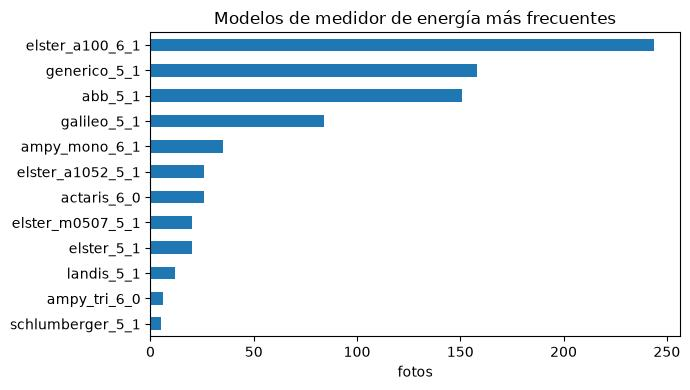

In [15]:
ax = energy["modelo"].value_counts().head(12).sort_values().plot.barh(figsize=(7, 4))
ax.set(title="Modelos de medidor de energía más frecuentes", xlabel="fotos", ylabel="")
plt.tight_layout()
plt.show()

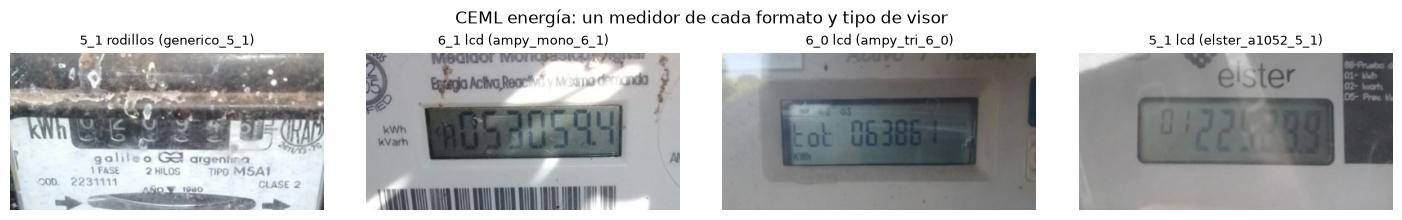

In [16]:
format_gallery(energy.assign(formato=energy["formato_tipo"].where(energy["formato"] != "sin modelo", "sin modelo")),
               ENERGY, "CEML energía: un medidor de cada formato y tipo de visor")

### Geometría del visor: energía contra agua

Las mismas medidas de la sección 3, sobre los visores de energía etiquetados (Roboflow, SAM 3 con revisión manual).

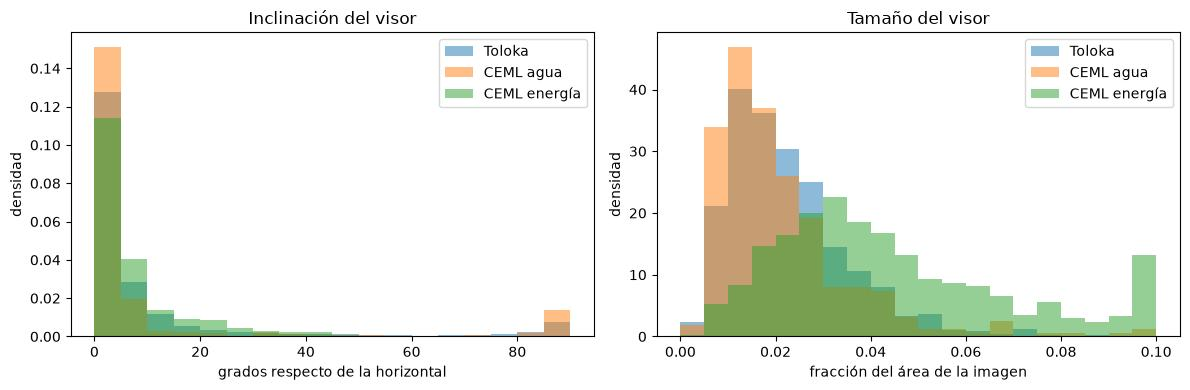

,Toloka,CEML,CEML energía,energía lcd,energía rodillos
inclinación mediana (°),2.9,1.9,4.0,5.0,3.7
% visores inclinados > 15°,16.0,13.0,16.0,21.7,11.8
área mediana del visor (%),2.0,1.7,3.8,4.0,3.5


In [17]:
rows = []
for r in energy.itertuples():
    with Image.open(ENERGY / "images" / r.file) as im:
        w, h = im.size
    area, tilt = display_geometry(yolo_polygon(ENERGY / "labels" / f"{Path(r.file).stem}.txt", w, h), w, h)
    rows.append({"file": r.file, "tipo": r.tipo, "width": w, "height": h, "area": area, "tilt": tilt})
energy_geo = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, geo in {"Toloka": toloka_geo, "CEML agua": ceml_geo, "CEML energía": energy_geo}.items():
    axes[0].hist(geo.tilt, bins=bins_tilt, alpha=0.5, density=True, label=name)
    axes[1].hist(geo.area.clip(upper=0.1), bins=bins_area, alpha=0.5, density=True, label=name)
axes[0].set(title="Inclinación del visor", xlabel="grados respecto de la horizontal", ylabel="densidad")
axes[1].set(title="Tamaño del visor", xlabel="fracción del área de la imagen", ylabel="densidad")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()


def geometry_summary(geo):
    return [geo.tilt.median(), (geo.tilt > 15).mean() * 100, geo.area.median() * 100]


summary["CEML energía"] = geometry_summary(energy_geo)
for tipo, geo in energy_geo.groupby("tipo"):
    summary[f"energía {tipo}"] = geometry_summary(geo)
summary.round(1)

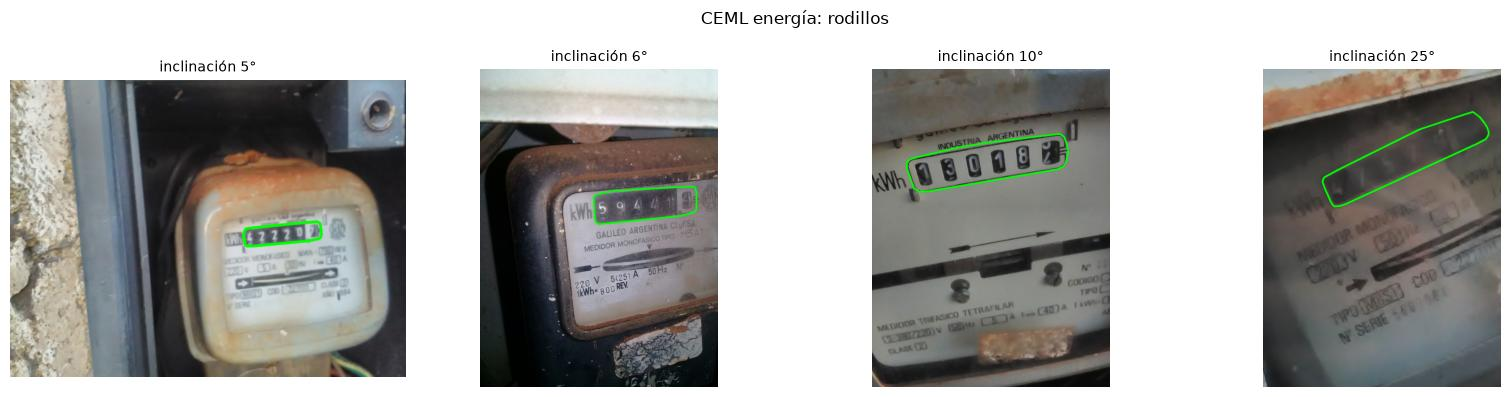

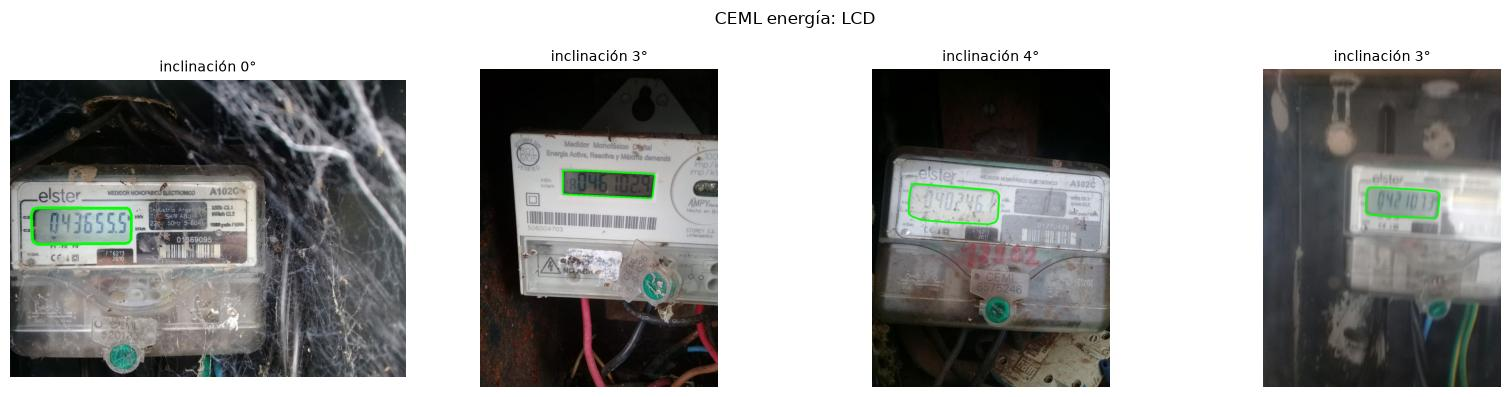

In [18]:
show_samples(energy_geo[energy_geo.tipo == "rodillos"], ENERGY / "images",
             lambda r: yolo_polygon(ENERGY / "labels" / f"{Path(r.file).stem}.txt", r.width, r.height),
             "CEML energía: rodillos")
show_samples(energy_geo[energy_geo.tipo == "lcd"], ENERGY / "images",
             lambda r: yolo_polygon(ENERGY / "labels" / f"{Path(r.file).stem}.txt", r.width, r.height),
             "CEML energía: LCD")

### Dígitos de energía

No había dígitos etiquetados de estos medidores. Los dígitos se etiquetaron sobre los visores rectificados de las fotos de entrenamiento: el detector de agua propuso las cajas (`scripts/export_digit_prelabels.py`), se corrigieron en Roboflow y se importaron con `scripts/import_digit_labels.py`. Después se revisó cada recorte contra la lectura propuesta por el modelo (`digits/revision.csv`): **ok** (las cajas coinciden), **corregida** (se corrigió algún número) o **ilegible** (no se puede asegurar la lectura a ojo).

Recortes con cajas: 499


,recortes
estado,
ilegible,281
ok,190
corregida,28


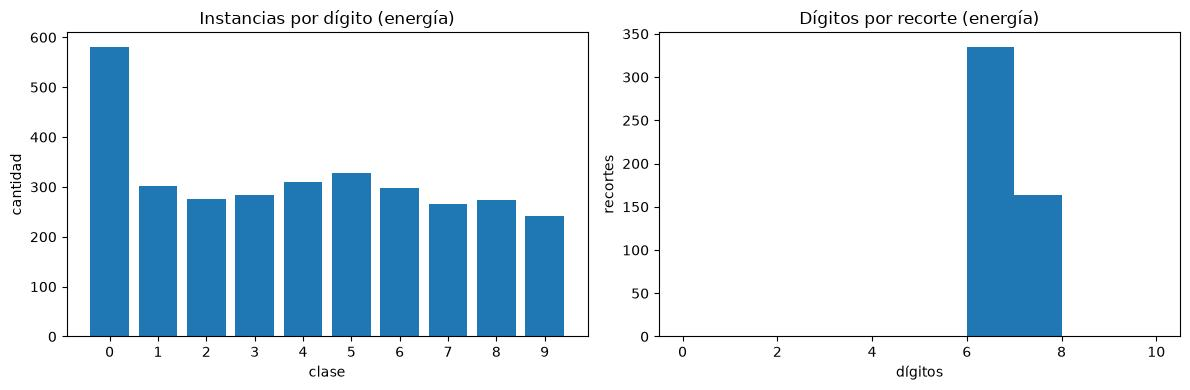

In [19]:
DIGITS = ENERGY / "digits"
revision = pd.read_csv(DIGITS / "revision.csv", dtype=str).fillna("")
print(f"Recortes con cajas: {len(list((DIGITS / 'labels').glob('*.txt')))}")
display(revision["estado"].value_counts().to_frame("recortes"))

class_counts, per_crop = Counter(), []
for label in (DIGITS / "labels").glob("*.txt"):
    classes = [int(line.split()[0]) for line in label.read_text().splitlines() if line.strip()]
    class_counts.update(classes)
    per_crop.append(len(classes))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar([str(d) for d in range(10)], [class_counts[d] for d in range(10)])
axes[0].set(title="Instancias por dígito (energía)", xlabel="clase", ylabel="cantidad")
axes[1].hist(per_crop, bins=range(0, 11))
axes[1].set(title="Dígitos por recorte (energía)", xlabel="dígitos", ylabel="recortes")
plt.tight_layout()
plt.show()

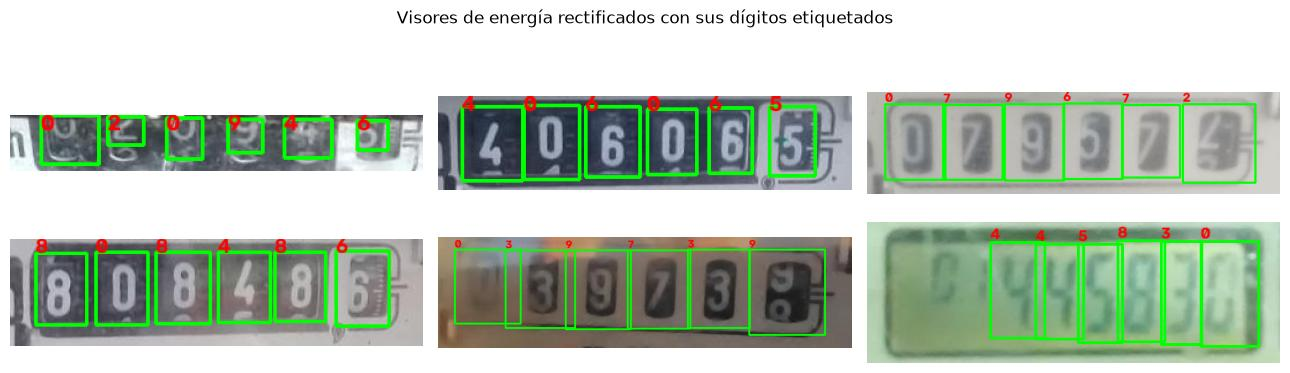

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(13, 4))
for ax, label in zip(axes.flat, sorted((DIGITS / "labels").glob("*.txt"))[::80]):
    img = np.array(Image.open(DIGITS / "images" / f"{label.stem}.jpg").convert("RGB"))
    h, w = img.shape[:2]
    for line in label.read_text().splitlines():
        c, x, y, bw, bh = line.split()
        x1, y1 = int((float(x) - float(bw) / 2) * w), int((float(y) - float(bh) / 2) * h)
        x2, y2 = int((float(x) + float(bw) / 2) * w), int((float(y) + float(bh) / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, c, (x1, max(y1 - 3, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
    ax.imshow(img)
    ax.axis("off")
fig.suptitle("Visores de energía rectificados con sus dígitos etiquetados")
plt.tight_layout()
plt.show()

### Dígitos LCD públicos

Dos datasets de Roboflow (CC BY 4.0) con dígitos de medidores LCD de 7 segmentos, que se suman a water-meter-dataset para entrenar el detector de dígitos (`digits_mix`). Son otros modelos de medidor, pero muestran el mismo tipo de dígito que los LCD de la cooperativa.

In [21]:
rows = []
for name in ("meter-digits-5srka", "meter-digits-frvqn"):
    if not (LCD / name / "data.yaml").exists():
        print(f"{name} no está descargado: se omite.")
        continue
    rows.append({"dataset": name, **{split: len(list((LCD / name / split / "images").glob("*")))
                                     for split in ("train", "valid", "test")}})
pd.DataFrame(rows).set_index("dataset") if rows else None

,train,valid,test
dataset,,,
meter-digits-5srka,2166,206,201
meter-digits-frvqn,1327,380,188


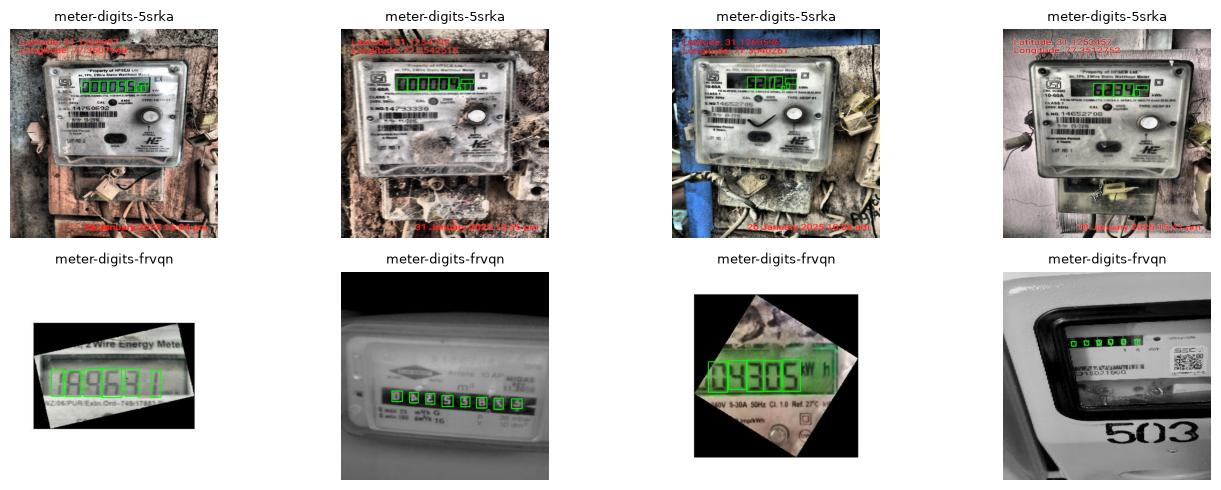

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for row, name in zip(axes, ("meter-digits-5srka", "meter-digits-frvqn")):
    files = sorted((LCD / name / "test" / "images").glob("*")) if (LCD / name).exists() else []
    for ax, image_path in zip(row, random.Random(1).sample(files, min(4, len(files)))):
        img = np.array(Image.open(image_path).convert("RGB"))
        h, w = img.shape[:2]
        for line in (LCD / name / "test" / "labels" / f"{image_path.stem}.txt").read_text().splitlines():
            values = list(map(float, line.split()[1:5]))
            if len(values) == 4:
                cx, cy, bw, bh = values
                cv2.rectangle(img, (int((cx - bw / 2) * w), int((cy - bh / 2) * h)),
                              (int((cx + bw / 2) * w), int((cy + bh / 2) * h)), (0, 255, 0), 2)
        ax.imshow(img)
        ax.set_title(name, fontsize=9)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Conclusiones

**Agua**

1. **La geometría del visor es similar en Toloka y CEML.** La inclinación mediana es de 2,9° y 1,9° respectivamente, y solo el 16 % y el 13 % de los visores supera los 15°. En ambos hay un grupo de visores verticales (cerca de 90°). La diferencia de dominio de CEML no está en la geometría sino en la **apariencia**: barro, reflejos, poca luz y tapas parcialmente cerradas.
2. **La rectificación aporta sobre todo en una minoría de casos.** Por eso el experimento A/B (recorte por caja contra máscara + rectificación) conviene mirarlo también por inclinación: un promedio global diluye el efecto. Así resultó (`03_resultados.ipynb`, sección 6): con el visor a más de 15°, el recorte por caja no lee ninguna foto.
3. **El visor es un objeto pequeño:** ocupa una mediana del 2,0 % (Toloka) y 1,7 % (CEML) del área de la imagen. Esto justifica el pipeline en dos etapas: segmentar el visor primero y leer los dígitos sobre el recorte, en lugar de detectar dígitos sobre la imagen completa.
4. **El dígito 0 está sobrerrepresentado** (unas 3 veces más instancias que el resto) por los ceros a la izquierda de las lecturas. Conviene reportar métricas por clase en el detector de dígitos.
5. **Las lecturas tienen típicamente entre 6 y 8 dígitos** anotados por imagen, lo que permite validar la salida del pipeline por longitud.

**Energía**

6. **Energía mezcla dos tipos de visor**: 451 fotos de rodillos y 337 de LCD, de 750 medidores y 24 rutas. Las 201 de la muestra de prueba (101 de rodillos y 100 LCD) quedan aparte, y 18 fotos más se excluyen del entrenamiento por ser de medidores de la muestra.
7. **Los formatos de energía son otros**: casi todos con un dígito de fracción (`5_1` y `6_1`). Los rodillos son todos `5_1`; los LCD son mayormente `6_1`, pero también `6_0` y `5_1`: el tipo de visor no alcanza para saber el formato, hace falta el clasificador.
8. **El visor de energía es más grande y algo más inclinado**: ocupa una mediana del 3,8 % de la foto (1,7 % en agua) y su inclinación mediana es de 4,0° (1,9° en agua). Los LCD son los más inclinados: el 21,7 % supera los 15°. Con visores más inclinados, rectificar importa más: en energía suma +15,0 puntos de lectura exacta, contra +7,6 en agua (`03_resultados.ipynb`, sección 6).
9. **Los dígitos de energía se etiquetaron sobre el visor rectificado**: 499 recortes con 6 o 7 dígitos cada uno. El 0 vuelve a ser el dígito más frecuente (unas 2 veces más que el resto, por los ceros a la izquierda). La revisión marcó 281 recortes como ilegibles a ojo: el criterio fue estricto, y por eso se entrenó con y sin ellos (`03_resultados.ipynb`, sección 3).
10. **Los LCD públicos aportan volumen**: unas 4500 imágenes entre 5srka y frvqn, con el mismo tipo de dígito de 7 segmentos que los LCD de la cooperativa.

*Limitación:* la inclinación se mide sobre el polígono y no distingue un visor invertido (180°) de uno derecho; ese caso se analiza en la etapa de lectura de dígitos (`03_resultados.ipynb`, sección 4).